# Industry Project: Semantic Search for a Help Center (Production-Style)

> **Who is this notebook for?** Someone who wants to build the search box of a real help center (or the "R" in a RAG chatbot) and has never done it before.
> No math is required. Every step is explained in plain English, and almost every line of code has a comment.

---

### How this notebook is different from the theory notebooks

| `09_sentence_embeddings_advanced.ipynb` / `10_advanced_nlp_tasks.ipynb` (theory) | This notebook (industry) |
|---|---|
| Explain **what** SBERT, BM25 and dense retrieval are | Builds and **measures** a complete search engine |
| A few example sentences | A knowledge base of ~250 articles with look-alike "distractor" pages, plus a **labelled query set** |
| "Dense beats keywords" as a claim | Recall@k, MRR and nDCG **per query type** (keywords, paraphrases, typos, deep sections) |
| No engineering | Chunking, FAISS index, hybrid search, re-ranking, saving the index, a search API with snippets, latency, and "no good answer" detection |

---

### The business problem

**"FinchBooks"** (a fictional online accounting app for small businesses) has a help center with a few hundred articles. Today its search box uses exact keyword matching. The support team says:

- Customers type how they *talk*: "I'm locked out" instead of "reset password". Keyword search finds nothing, so they open a ticket.
- Customers make **typos**.
- Every ticket costs about **\$6**. If better search answers even 10% more of the ~15,000 monthly searches, that is thousands of dollars per month.
- When the help center has **no** answer, search should say so honestly (and offer a "contact us" button) instead of showing random articles.

**Success metrics:** *Recall@5* (is a correct article in the top 5 results?), *MRR* (how high is the first correct article?), latency under ~100 ms per search on a CPU, and a reliable "no good answer" flag.

---

### Table of Contents
1. Setup: imports and one central config
2. The knowledge base (corpus)
3. The evaluation set: labelled queries
4. Chunking long documents
5. Baseline: BM25 keyword search
6. Dense retrieval: sentence embeddings + FAISS
7. Evaluation: Recall@k, MRR, nDCG per query type
8. Why chunking matters
9. Hybrid search with Reciprocal Rank Fusion (RRF)
10. Re-ranking with a cross-encoder
11. Error analysis, and a business rule
12. Choosing the production setup honestly (dev / test queries)
13. Latency: what does each stage cost?
14. "No good answer" detection with a score threshold
15. Save and reload the index
16. The search API: validated input, snippets, answer flag
17. Scaling up and automated tests
18. Summary, exercises and resources

---
## 1. Setup: imports and one central config

Two small pretrained models are used (both download once, ~90 MB each, then are cached):
- **Bi-encoder** `all-MiniLM-L6-v2`: turns any text into a 384-number vector. Fast; used to search the whole corpus.
- **Cross-encoder** `ms-marco-MiniLM-L6-v2`: reads the query **and** a document together and outputs a relevance score. More accurate but slower, so it is only used to re-order the top few results.

In [1]:
# ---- Standard library ----
import hashlib                    # fingerprint of the corpus, stored with the index
import json                       # save chunks and metadata
import logging                    # status messages
import os                         # environment variables
import re                         # tokenising and highlighting
import tempfile                   # temporary folder for the saved index (keeps the repo clean)
import time                       # latency measurements
import warnings
from collections import defaultdict
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from pathlib import Path

warnings.filterwarnings("ignore")                # keep the tutorial output clean (set before imports)
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"  # no download progress bars

# ---- Third-party ----
import faiss                      # Facebook AI Similarity Search: fast vector search
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from nltk.corpus import stopwords                 # common words like "the", "and"
from nltk.stem import PorterStemmer               # "invoices" -> "invoic", "invoicing" -> "invoic"
from rank_bm25 import BM25Okapi                   # the classic keyword ranking function
import transformers
from sentence_transformers import CrossEncoder, SentenceTransformer

transformers.logging.set_verbosity_error()        # hide model-loading messages and progress bars
transformers.logging.disable_progress_bar()
# Root logger at WARNING hides the chatty HTTP/download logs of libraries; our own logger shows INFO
logging.basicConfig(level=logging.WARNING, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("kb_search")
log.setLevel(logging.INFO)
torch.set_num_threads(4)          # be a good neighbour on a shared CPU machine


@dataclass(frozen=True)
class Config:
    random_state: int = 42
    bi_encoder: str = "sentence-transformers/all-MiniLM-L6-v2"
    cross_encoder: str = "cross-encoder/ms-marco-MiniLM-L6-v2"
    chunk_words: int = 110           # target chunk size in words (MiniLM reads at most 256 word pieces)
    chunk_overlap: int = 25          # words shared by neighbouring chunks, so no sentence is cut off alone
    candidates: int = 50             # chunks fetched from each retriever before merging
    rrf_k: int = 60                  # the standard constant of Reciprocal Rank Fusion
    rerank_depth: int = 15           # how many top documents the cross-encoder re-scores
    top_k: int = 10                  # results evaluated / returned


CFG = Config()
rng = np.random.default_rng(CFG.random_state)
log.info("faiss %s | torch %s", faiss.__version__, torch.__version__)
print(CFG)

2026-10-21 17:45:31,767 | INFO | faiss 1.14.3 | torch 2.12.1+cpu


Config(random_state=42, bi_encoder='sentence-transformers/all-MiniLM-L6-v2', cross_encoder='cross-encoder/ms-marco-MiniLM-L6-v2', chunk_words=110, chunk_overlap=25, candidates=50, rrf_k=60, rerank_depth=15, top_k=10)


---
## 2. The knowledge base (corpus)

In a real company you would export the help center from its CMS (Zendesk Guide, Confluence, Intercom...) as JSON. Here we write it in the notebook. It has four kinds of documents, like a real help center:

| Kind | Count | Why it matters for search |
|---|---|---|
| **Core how-to articles** | 52 | The answers customers need |
| **Long guides** (handbooks, whitepapers) | 3 | 500+ words each; the answer may be hidden in section 6 |
| **Template pages** (integrations, country tax pages, report glossary) | ~90 | Many near-identical pages: "Connect Slack", "Connect Dropbox"... hard for any search engine |
| **Release notes & known issues** | ~110 | Full of feature keywords but rarely the right answer: they "steal" keyword matches |

You can skim this cell: the content is just text.

In [2]:
CORE_ARTICLES = [  # (doc_id, category, title, body)
 ("KB-001", "Account", "Reset your password", "If you forgot your password, click 'Forgot password?' on the sign-in page and enter the email address of your FinchBooks account. We send a reset link that is valid for 30 minutes. Check your spam folder if the email does not arrive. For security, resetting your password signs you out on all devices."),
 ("KB-002", "Account", "Change the email address on your account", "Go to Profile > Login details and click Edit next to your email address. Enter the new address and confirm it with the verification link we send to it. Until you confirm, you keep signing in with the old address."),
 ("KB-003", "Security", "Turn on two-factor authentication (2FA)", "Two-factor authentication adds a one-time code to your sign-in. Open Profile > Security, choose 'Enable 2FA' and scan the QR code with an authenticator app. Save the ten recovery codes in a safe place; each code works once."),
 ("KB-004", "Security", "Lost access to your authenticator app", "If your phone is lost or reset and you cannot generate 2FA codes, sign in with one of your recovery codes and set up 2FA again. Without recovery codes, the account owner must verify their identity with our support team, which takes up to two business days."),
 ("KB-005", "Account", "Delete your FinchBooks account", "Only the account owner can permanently delete an account. Cancel any paid subscription first, then go to Settings > Account > Delete account. Deletion removes all companies, invoices and attachments after a 14-day grace period and cannot be undone."),
 ("KB-006", "Team", "Invite team members and your accountant", "Open Settings > Users and click Invite user. Enter their email address and choose a role. Accountants and bookkeepers can be invited for free with the Accountant role and get their own login to your books."),
 ("KB-007", "Team", "User roles and permissions", "FinchBooks has four roles: Owner, Admin, Standard and Read-only. Standard users can create invoices and expenses but cannot see payroll reports, bank details or settings. Custom roles let you hide specific modules from specific people."),
 ("KB-008", "Team", "Remove a user from your workspace", "When someone leaves your company, open Settings > Users, select the person and click Remove access. Their sign-in stops working immediately; the invoices and expenses they created stay in your books."),
 ("KB-009", "Security", "Set up single sign-on (SSO) with SAML", "On the Enterprise plan, admins can let employees sign in through your identity provider such as Okta, Azure Active Directory or Google Workspace. Upload the SAML metadata file under Settings > Security > Single sign-on and test the connection before enforcing it."),
 ("KB-010", "Billing", "Upgrade or downgrade your plan", "Go to Settings > Billing > Change plan. Upgrades apply immediately and you pay the difference for the rest of the billing period. Downgrades take effect at the next renewal date; features of the higher tier stay available until then."),
 ("KB-011", "Billing", "Cancel your subscription", "Open Settings > Billing and click Cancel subscription. You keep access until the end of the period you already paid for, and your plan will not renew. Your data stays available in read-only mode for 12 months."),
 ("KB-012", "Billing", "Update your payment method", "If your card expired or was replaced, go to Settings > Billing > Payment method and add the new card. We retry failed payments three times over seven days before the account is paused."),
 ("KB-013", "Billing", "Download receipts for your FinchBooks subscription", "Every charge for your FinchBooks plan has a PDF receipt with our VAT number. Find them under Settings > Billing > Billing history and download them for your expense reports or your accountant."),
 ("KB-014", "Billing", "Request a refund", "If you were charged twice or by mistake, contact support within 30 days of the charge and we refund it to the original card. Annual plans cancelled within the first 14 days are refunded in full."),
 ("KB-015", "Billing", "What happens when your free trial ends", "The free trial lasts 14 days and includes all features. If you do not add a payment method, the account switches to read-only when the trial ends; nothing is deleted, and you can subscribe at any time to continue."),
 ("KB-016", "Billing", "Discounts for non-profits and students", "Registered charities and non-profit organisations get 50% off any plan. Students and teachers can use the Starter plan for free with a school email address. Apply through the discount form with proof of status."),
 ("KB-017", "Invoices", "Create and send an invoice", "Click New > Invoice, pick a customer, add line items with quantity and price, and click Send. The customer receives an email with a link to view, download and pay the invoice. You can also download it as PDF and send it yourself."),
 ("KB-018", "Invoices", "Set up recurring invoices", "For customers you bill the same amount regularly, open an invoice and choose Make recurring. Select the frequency (weekly, monthly, yearly), the start date and whether it is sent automatically or saved as a draft for review."),
 ("KB-019", "Invoices", "Customise invoice templates and add your logo", "Under Settings > Templates you can upload your logo, choose brand colours and fonts, and add payment terms or a thank-you note. Each template can be set as default for a customer."),
 ("KB-020", "Invoices", "Send automatic payment reminders", "Turn on Reminders under Settings > Invoices to email customers before and after the due date. You can edit the wording of each reminder and stop reminders for individual customers."),
 ("KB-021", "Invoices", "Accept online card payments on invoices", "Connect a payment provider under Settings > Online payments. A Pay now button then appears on every invoice email, so customers can pay by credit card or bank transfer. The invoice is marked as paid automatically."),
 ("KB-022", "Invoices", "Record a partial payment", "When a customer pays only part of an invoice, open it and click Record payment. Enter the amount received and the date; the remaining balance stays open and appears in the aged receivables report."),
 ("KB-023", "Invoices", "Issue a credit note", "A credit note reduces what a customer owes, for example after returned goods or a pricing mistake. Open the original invoice, choose More > Create credit note and select the lines to credit. Credit notes can be refunded or applied to a future invoice."),
 ("KB-024", "Invoices", "Invoice in a foreign currency", "Multi-currency is available on the Plus plan. Set the customer's currency on their contact page; invoices are then issued in that currency and converted to your home currency with the daily exchange rate for reporting."),
 ("KB-025", "Invoices", "Change the invoice number sequence", "Invoice numbers increase automatically. To start from a different number or add a prefix like INV-2026-, go to Settings > Invoices > Numbering. Changing the sequence does not renumber existing invoices."),
 ("KB-026", "Banking", "Connect your bank account", "Bank feeds import your transactions automatically every day. Open Banking > Add bank account, search for your bank and sign in through its secure page. Over 10,000 banks are supported; you can also upload statements as CSV."),
 ("KB-027", "Banking", "Bank feed is not updating", "If new transactions are missing, open Banking and click Refresh. Many banks require you to re-authorise access every 90 days; a yellow banner shows when this is needed. Transactions can take up to 24 hours to appear after they clear at the bank."),
 ("KB-028", "Banking", "Reconcile bank transactions", "Reconciling means matching each bank line with a record in your books. Open Banking > Reconcile; FinchBooks suggests matches for invoices, bills and expenses. Accept a suggestion, or create a new record for unmatched lines."),
 ("KB-029", "Expenses", "Scan receipts with the mobile app", "In the mobile app, tap the camera button and photograph a receipt. Text recognition fills in the merchant, date, amount and tax automatically, and the picture is attached to the expense as proof."),
 ("KB-030", "Expenses", "Categorise expenses automatically with rules", "Rules assign a category to matching transactions, for example every payment containing 'taxi' goes to Travel. Create rules under Banking > Rules with conditions on description, amount or contact."),
 ("KB-031", "Expenses", "Track mileage for business trips", "Log business journeys under Expenses > Mileage with start and end address; the distance and the claimable amount are calculated with your country's standard rate per kilometre or mile."),
 ("KB-032", "Reports", "Profit and loss report", "The profit and loss report (income statement) shows income minus expenses for a period, so you can see whether your business made money. Open Reports > Profit and loss, choose the date range and compare with the previous period."),
 ("KB-033", "Reports", "Export your data to CSV or Excel", "Most lists and reports have an Export button that downloads a CSV or Excel file. To export everything at once, use Settings > Data > Export all, which creates a zip file of spreadsheets."),
 ("KB-034", "Tax", "Add a custom tax rate", "Besides the standard rates of your country, you can create custom tax rates under Settings > Taxes > Add rate, for example a reduced rate for some products or a zero rate for exempt items. Assign a default rate to each product."),
 ("KB-035", "Reports", "Lock a period after closing your books", "After filing your taxes, set a lock date under Settings > Advanced > Lock date. Nobody can add, edit or delete transactions dated before it, which protects the figures you already reported."),
 ("KB-036", "Reports", "Share reports with your accountant", "Invite your accountant with the free Accountant role, or send a report directly: open it, click Share and enter an email address. Shared links expire after 30 days."),
 ("KB-037", "Mobile", "Install the mobile app", "The FinchBooks app is available for iPhone, iPad and Android phones. Download it from the App Store or Google Play and sign in with your usual account; all data is synced with the web version."),
 ("KB-038", "Mobile", "Work offline", "The mobile app keeps working without an internet connection. You can create invoices, expenses and receipts while offline, and they are synced as soon as you are back online."),
 ("KB-039", "Mobile", "Turn on push notifications", "In the mobile app open Settings > Notifications to choose alerts such as 'invoice paid', 'invoice overdue' or 'new bank transaction'. Make sure notifications for FinchBooks are allowed in your phone settings."),
 ("KB-040", "Technical", "Supported browsers and system requirements", "FinchBooks works in the latest two versions of Chrome, Firefox, Safari and Edge. Internet Explorer is not supported. If pages look broken, clear your browser cache or try a private window."),
 ("KB-041", "Privacy", "Request a copy of your personal data (GDPR)", "Under the GDPR you can request all personal data we hold about you. Go to Profile > Privacy > Download my data; we email a link to a machine-readable archive within 72 hours."),
 ("KB-042", "Privacy", "How long we keep your data after you cancel", "After cancellation your data stays in read-only mode for 12 months so you can export it. After that it is permanently deleted from our systems, including backups, within 90 days."),
 ("KB-043", "Privacy", "Where your data is stored", "Customer data is stored in data centres in Frankfurt (EU) or Virginia (US), depending on the region chosen at sign-up. EU customers' data never leaves the European Union."),
 ("KB-044", "Security", "How we protect your data", "All data is encrypted in transit with TLS 1.3 and at rest with AES-256. Access by employees is logged and limited to support cases you approve. See our security whitepaper for details."),
 ("KB-045", "Security", "View the audit log", "Admins can see who did what under Settings > Audit log: every created, edited or deleted invoice, payment and setting is listed with user, time and IP address. Filter by user or by date."),
 ("KB-046", "Developers", "Create an API key", "Developers can connect their own software through the REST API. Create a personal API key under Settings > Developers > API keys and send it in the Authorization header. Keys can be revoked at any time."),
 ("KB-047", "Developers", "API rate limits", "The API allows 120 requests per minute per company. If you exceed it, the API answers with HTTP status 429 Too Many Requests and a Retry-After header. Use pagination and webhooks instead of polling."),
 ("KB-048", "Developers", "Set up webhooks", "Webhooks send an HTTP POST request to your server when an event happens, such as invoice.paid or contact.created. Register the URL under Settings > Developers > Webhooks and verify the signature header."),
 ("KB-049", "Support", "Contact support", "Our support team answers chat and email Monday to Friday, 8:00 to 20:00 CET. Phone support is included on the Plus and Enterprise plans. Use the Help button in the app to start a chat."),
 ("KB-050", "Getting started", "Import data from another accounting tool", "Use the import wizard under Settings > Data > Import to move customers, products, invoices and opening balances from a spreadsheet or from another accounting system. Download the CSV template first."),
 ("KB-051", "Account", "Manage several companies with one login", "One login can access several companies, each with its own books, bank accounts and subscription. Use the company switcher in the top-left corner to move between them."),
 ("KB-052", "Account", "Change language and date format", "Choose your language, date format (for example DD/MM/YYYY) and number format under Profile > Preferences. The language of invoices sent to customers is set per customer."),
]

LONG_GUIDES = {  # doc_id -> (title, [(section title, section text), ...])
 "KB-090": ("FinchBooks Administrator Handbook", [
   ("Overview", "This handbook is for workspace administrators. It explains the admin console, how settings apply to every user, and the responsibilities of an admin. Most pages of the console are only visible to users with the Owner or Admin role, and every change made there is recorded."),
   ("Workspace settings", "Workspace settings control the company name, address, logo, fiscal year and home currency. Changing the fiscal year start affects all reports, so do it before you record transactions. The home currency cannot be changed after the first invoice has been issued."),
   ("Seats and licences", "Each paid plan includes a number of seats. Adding users beyond your seats increases your bill from the next period. Read-only users and accountants do not use a seat. You can see seat usage on the Billing page at any time."),
   ("Password policy", "Admins can enforce a password policy for all users: a minimum length of 12 to 32 characters, required symbols, and password expiry after 30, 60 or 90 days. Users are asked to choose a new password at their next sign-in after the policy changes."),
   ("Session timeout and IP allowlist", "To reduce risk on shared computers, set an automatic sign-out after 15 minutes to 12 hours of inactivity. On the Enterprise plan you can also restrict sign-ins to an IP allowlist, for example only from your office network or VPN addresses."),
   ("Backups and restore", "We back up all data every six hours and keep backups for 35 days. Deleted invoices and contacts can be restored from the recycle bin for 30 days. To restore a complete company to an earlier point in time, the account owner must contact support."),
   ("Offboarding checklist", "When an employee leaves: remove their access, transfer open tasks and approvals, rotate any API keys they created, and review the audit log for their last actions. Removing a user never deletes the records they created."),
   ("Transferring ownership", "Every company has exactly one owner, who controls billing and deletion. To hand the company over, the current owner opens Settings > Users, chooses a person with the Admin role and selects Transfer ownership. The new owner must accept the transfer by email."),
 ]),
 "KB-091": ("Year-End Closing Guide", [
   ("Why close your year", "Closing the financial year makes sure your reports are complete and correct before you file taxes. This guide walks you through the steps in order. Plan about two hours for a small business with up to a few hundred transactions per month."),
   ("Review open invoices and bills", "Open the aged receivables and aged payables reports. Chase or write off invoices that will never be paid, and make sure every bill you received is entered. Uncollectable invoices are recorded as bad debt."),
   ("Reconcile every account", "Reconcile all bank, credit card and loan accounts up to the last day of the year. The closing balance in FinchBooks must match the bank statement exactly; differences usually come from duplicated or missing transactions."),
   ("Depreciation of fixed assets", "Equipment, vehicles and computers lose value over time. Register them under Accounting > Fixed assets with their purchase price and useful life; FinchBooks then calculates straight-line or declining-balance depreciation and posts the yearly depreciation entry for you."),
   ("Inventory count", "If you hold stock, count it on the last day of the year. Enter the counted quantities under Products > Stock adjustment; FinchBooks books the difference between counted and recorded stock as an inventory adjustment."),
   ("Lock the period", "After your accountant has checked the figures, set the lock date to the last day of the year so that nobody changes the closed period by accident."),
   ("Annual contractor forms", "In the United States, businesses must send Form 1099-NEC to contractors paid 600 dollars or more. Mark contacts as 1099 contractors and FinchBooks prepares the forms and the summary for e-filing in January."),
   ("Opening the new year", "Retained earnings are carried forward automatically. Review your budget for the new year, update tax rates that changed, and archive products and customers you no longer use."),
 ]),
 "KB-092": ("Security and Compliance Whitepaper", [
   ("Infrastructure", "FinchBooks runs on a major cloud provider in isolated networks across several availability zones. Production systems are monitored around the clock and every change goes through code review and automated testing."),
   ("Encryption", "Data in transit is protected with TLS 1.3. Data at rest, including backups and attachments, is encrypted with AES-256 and keys are rotated regularly using a hardware security module."),
   ("Penetration tests and bug bounty", "Independent security firms test the application twice a year. We also run a public bug bounty programme: security researchers who report a vulnerability responsibly through our disclosure page are rewarded."),
   ("Certifications and audit reports", "FinchBooks is certified to ISO 27001 and audited every year for SOC 2 Type II. Customers on the Enterprise plan can download the latest SOC 2 report from the Trust portal after signing a non-disclosure agreement."),
   ("Incident response", "We maintain a tested incident response plan. If a personal data breach affects your account, we notify the account owner without undue delay and at the latest within 72 hours, as required by the GDPR."),
   ("Employee access", "Employees get the minimum access they need. Access to customer data requires a support case approved by the customer, multi-factor authentication and is logged and reviewed monthly."),
   ("Sub-processors", "We use a small number of sub-processors for hosting, email delivery and payments. The current list and their locations are published on our website, and customers are informed 30 days before a new sub-processor is added."),
 ]),
}

print(f"{len(CORE_ARTICLES)} core articles and {len(LONG_GUIDES)} long guides written by hand")

52 core articles and 3 long guides written by hand


Now the **template pages and release notes**. Real help centers have hundreds of these near-identical pages, and they are what makes search hard: "Troubleshoot Slack sync errors" and "Troubleshoot Dropbox sync errors" differ by a single word.

In [3]:
INTEGRATIONS = {  # name -> what the integration does
    "Slack": "posts a message to a channel when an invoice is paid or overdue",
    "Google Drive": "saves a PDF copy of every invoice and receipt in a folder",
    "Dropbox": "stores attachments and receipts in your Dropbox folder",
    "Shopify": "turns every online store order into a sales invoice with taxes",
    "Stripe": "imports card payments and payouts and matches them to invoices",
    "PayPal": "imports PayPal transactions and fees into your books",
    "Zapier": "connects FinchBooks to thousands of apps with automated workflows (Zaps)",
    "HubSpot": "creates customers in FinchBooks from deals won in your CRM",
    "Microsoft Teams": "sends notifications about payments to a Teams channel",
    "Gmail": "lets you create expenses from emailed receipts",
    "Outlook": "lets you send invoices from your own Outlook address",
    "Mailchimp": "syncs your customer list for newsletters",
    "Square": "imports point-of-sale sales and card fees",
    "WooCommerce": "creates invoices from orders in your WordPress shop",
    "Salesforce": "syncs accounts and closed opportunities with your customers",
}
COUNTRIES = {"Germany": 19, "France": 20, "United Kingdom": 20, "Spain": 21, "Italy": 22, "Netherlands": 21,
             "Belgium": 21, "Austria": 20, "Ireland": 23, "Portugal": 23, "Sweden": 25, "Denmark": 25,
             "Norway": 25, "Finland": 25.5, "Poland": 23, "Czech Republic": 21, "Switzerland": 8.1,
             "Canada": 5, "Australia": 10, "New Zealand": 15, "Singapore": 9, "India": 18, "Japan": 10,
             "South Africa": 15, "Mexico": 16, "Brazil": 17, "United States": 0, "Greece": 24,
             "Hungary": 27, "Romania": 19}
REPORTS = ["Balance sheet", "Cash flow", "Aged receivables", "Aged payables", "Sales by customer",
           "Expenses by category", "Tax summary", "Trial balance", "General ledger", "Budget vs actual",
           "Project profitability", "Inventory valuation"]
CHANGES = [  # sentences used to build release notes (keyword-rich but rarely the right answer)
    "Recurring invoices can now be paused and resumed.", "Fixed a bug where some bank feeds stopped updating.",
    "Two-factor authentication now supports hardware security keys.", "The password reset email has a new design.",
    "Credit notes can now be applied to several invoices.", "Faster loading of the profit and loss report.",
    "New custom fields on invoice templates.", "Payment reminders can be sent by SMS in selected countries.",
    "The mobile app can scan multi-page receipts.", "CSV export now includes custom fields.",
    "Improved matching suggestions when you reconcile.", "Webhooks now include the event id for de-duplication.",
    "The API supports filtering invoices by status.", "New user role: Sales (invoices only).",
    "Dark mode in the mobile app.", "Fixed: exchange rates for some currencies were a day late.",
    "Audit log entries can be exported.", "Mileage rates updated for the new tax year.",
    "Offline mode now supports editing customers.", "Single sign-on now supports SCIM user provisioning.",
    "Fixed an issue where push notifications arrived twice.", "Invoice numbering prefixes can contain the year.",
    "Faster search in the help center.", "New integration settings page.",
    "Subscription receipts now show your VAT number.", "Bulk delete for draft invoices.",
    "Improved text recognition for handwritten receipts.", "Rules can now match on amount ranges.",
]
PLATFORMS = ["iOS app", "Android app", "Safari", "Firefox", "Edge", "Chrome"]
FEATURES = ["Invoice PDF preview", "Bank feed refresh", "Receipt scanning", "Report export", "Payment reminders",
            "Sign-in with SSO", "Dashboard charts", "Mileage tracking", "Push notifications", "Credit notes"]


def build_template_docs() -> list[tuple[str, str, str, str]]:
    docs, n = [], 100
    def add(category, title, body):
        nonlocal n
        n += 1
        docs.append((f"KB-{n:03d}", category, title, body))
    for name, purpose in INTEGRATIONS.items():
        add("Integrations", f"Connect {name} to FinchBooks",
            f"The {name} integration {purpose}. To connect it, open Settings > Integrations, find {name} and "
            f"click Connect. You are redirected to {name} to approve access, then sent back to FinchBooks.")
        add("Integrations", f"Troubleshoot {name} sync errors",
            f"If the {name} integration stops syncing, first check the status on Settings > Integrations. "
            f"Expired permissions are the most common cause: click Reconnect and approve access in {name} again. "
            f"Sync errors are listed with the date and the record that failed.")
        add("Integrations", f"Disconnect {name}",
            f"To disconnect {name}, open Settings > Integrations, select {name} and click Disconnect. "
            f"Data that was already synced stays in FinchBooks; nothing is deleted in {name}.")
    for country, rate in COUNTRIES.items():
        add("Tax", f"Sales tax and VAT settings for {country}",
            f"For companies registered in {country}, FinchBooks pre-configures the standard rate of {rate}% "
            f"and the common reduced rates. Enter your tax registration number under Settings > Taxes "
            f"to show it on invoices, and choose your filing period.")
    for report in REPORTS:
        add("Reports", f"Understanding the {report} report",
            f"The {report.lower()} report is available under Reports. Choose a date range, filter by "
            f"customer, project or category, and export it to PDF or CSV. This article explains each column.")
    for i in range(80):
        changes = rng.choice(CHANGES, size=3, replace=False)
        add("Release notes", f"Release notes - version 7.{i}", " ".join(changes))
    for i in range(30):
        feature, platform = FEATURES[i % len(FEATURES)], PLATFORMS[rng.integers(len(PLATFORMS))]
        add("Known issues", f"Known issue: {feature} on {platform}",
            f"Some customers report that {feature.lower()} is slow or fails on {platform}. Our engineers are "
            f"working on a fix. As a workaround, use another browser or update the app to the latest version.")
    return docs


def build_corpus() -> pd.DataFrame:
    rows = [dict(doc_id=d, category=c, title=t, body=b) for d, c, t, b in CORE_ARTICLES + build_template_docs()]
    for doc_id, (title, sections) in LONG_GUIDES.items():
        body = "\n\n".join(f"## {s_title}\n{s_text}" for s_title, s_text in sections)  # Markdown-style sections
        rows.append(dict(doc_id=doc_id, category="Guides", title=title, body=body))
    corpus = pd.DataFrame(rows)
    corpus["n_words"] = corpus["body"].str.split().str.len()
    return corpus


corpus = build_corpus()
assert corpus["doc_id"].is_unique
print(f"Corpus: {len(corpus)} documents | words per document: median {corpus['n_words'].median():.0f}, "
      f"max {corpus['n_words'].max()}")
print(corpus["category"].value_counts().to_string())

Corpus: 252 documents | words per document: median 33, max 365
category
Release notes      80
Integrations       45
Tax                31
Known issues       30
Reports            16
Invoices            9
Billing             7
Account             5
Security            5
Team                3
Expenses            3
Developers          3
Mobile              3
Banking             3
Privacy             3
Guides              3
Technical           1
Getting started     1
Support             1


---
## 3. The evaluation set: labelled queries

**This is the most valuable asset of a search project.** Without a labelled query set, you cannot tell if a change made search better or worse; you only have opinions.

In a company you build it from **search logs** (what people really typed) and ask support agents to mark the correct article(s). The famous public benchmark **BEIR** works the same way: queries + "qrels" (query relevance labels).

We use five query types, because a single average hides important differences:

| Type | Example | What it tests |
|---|---|---|
| `keyword` | "reset password" | Words that appear in the article |
| `paraphrase` | "forgot my login and I'm locked out" | Same meaning, **different words** |
| `typo` | "resett pasword" | Misspellings (generated automatically from the keyword queries) |
| `deep_section` | "IP allowlist for our office network" | Answer hidden deep inside a long guide |
| `integration` | "Slack messages stopped when invoices get paid" | Picking the right page among near-identical templates |

Plus **`no_answer`** queries, for which the help center has nothing: search should admit it.

In [4]:
QUERIES = {  # doc_id -> (keyword query, paraphrase query)
 "KB-001": ("reset password", "forgot my login and now I'm locked out"),
 "KB-002": ("change account email address", "I got a new work address and want to sign in with it instead"),
 "KB-003": ("enable two-factor authentication", "add an extra code from my phone when logging in"),
 "KB-004": ("lost authenticator app recovery codes", "my phone was stolen and I can't get the six digit code anymore"),
 "KB-005": ("delete account permanently", "remove my whole profile and everything in it for good"),
 "KB-006": ("invite team members", "how can the person who does my bookkeeping get their own access"),
 "KB-007": ("user roles and permissions", "stop an employee from seeing bank details but let them make bills"),
 "KB-008": ("remove user access", "a colleague quit, how do I make sure she can't log in anymore"),
 "KB-009": ("SAML single sign-on setup", "let staff log in with our corporate Okta identity"),
 "KB-010": ("upgrade or downgrade plan", "move to a cheaper tier because our team got smaller"),
 "KB-011": ("cancel subscription", "stop paying every month, I don't want it to renew"),
 "KB-012": ("update payment method card", "my card expired, where do I put the new one"),
 "KB-013": ("download subscription receipts", "need a copy of what you charged me last month for my expense claim"),
 "KB-014": ("request a refund", "you took money from me two times, I want it back"),
 "KB-015": ("free trial ends", "what happens after the 14 days if I never enter card details"),
 "KB-016": ("non-profit discount", "is there a cheaper price for charities"),
 "KB-017": ("create and send invoice", "bill a client for work I did"),
 "KB-018": ("recurring invoices", "charge the same client automatically every month"),
 "KB-019": ("invoice template logo", "make the bills I send look like my brand with our colours"),
 "KB-020": ("automatic payment reminders", "nudge clients who haven't paid yet without writing emails myself"),
 "KB-021": ("accept card payments on invoices", "let my clients pay me straight from the email"),
 "KB-022": ("record partial payment", "customer paid only half of what they owe, how do I note that"),
 "KB-023": ("issue credit note", "give a customer money back for goods they returned"),
 "KB-024": ("invoice in foreign currency", "bill a client in euros while my books are in dollars"),
 "KB-025": ("invoice number sequence", "start my bill numbers at 1000 instead of 1"),
 "KB-026": ("connect bank account", "get my transactions from the bank to show up by themselves"),
 "KB-027": ("bank feed not updating", "yesterday's transactions are missing, the sync seems stuck"),
 "KB-028": ("reconcile bank transactions", "match what's on my bank statement with what's in the books"),
 "KB-029": ("scan receipts mobile app", "take a photo of a lunch bill with my phone and save it as an expense"),
 "KB-030": ("expense categorisation rules", "make every taxi ride go into travel automatically"),
 "KB-031": ("track mileage", "log the kilometres I drive for client visits"),
 "KB-032": ("profit and loss report", "see whether my business made money this quarter"),
 "KB-033": ("export data to csv excel", "get all my numbers out into a spreadsheet"),
 "KB-034": ("custom tax rate", "charge a reduced rate on some products and nothing on others"),
 "KB-035": ("lock date closed period", "prevent anyone from editing last year's numbers after filing"),
 "KB-036": ("share reports with accountant", "send the figures to the person who does my taxes"),
 "KB-037": ("install mobile app", "is there a version for my iPhone"),
 "KB-038": ("offline mode", "can I work on a plane without wifi"),
 "KB-039": ("push notifications", "get pinged on my phone when a client pays"),
 "KB-040": ("supported browsers", "the site looks broken in my old Internet Explorer"),
 "KB-041": ("GDPR personal data copy", "get a copy of all the information you store about me"),
 "KB-042": ("data retention after cancellation", "how long do you keep my records once I stop paying"),
 "KB-043": ("data storage location", "are my files kept on servers inside the EU"),
 "KB-044": ("data encryption security", "how do you protect my information from hackers"),
 "KB-045": ("audit log", "find out who deleted an invoice yesterday"),
 "KB-046": ("create API key", "connect my own software to my data with a token"),
 "KB-047": ("API rate limit 429", "my script gets 'too many requests' errors"),
 "KB-048": ("webhooks setup", "get a call to my server when an invoice is paid"),
 "KB-049": ("contact support hours", "talk to a real person"),
 "KB-050": ("import data from another accounting tool", "move my old records over from the system I used before"),
 "KB-051": ("manage several companies", "I run two shops, can I keep them separate under one sign-in"),
 "KB-052": ("change language date format", "show dates as day month year"),
}
DEEP_SECTION_QUERIES = [  # (query, doc_id): the answer is in a late section of a long guide
 ("restrict sign-in to our office IP addresses", "KB-090"),
 ("how often are backups made and can deleted invoices be restored", "KB-090"),
 ("transfer company ownership to another admin", "KB-090"),
 ("force users to change passwords every 90 days", "KB-090"),
 ("record depreciation on equipment and vehicles", "KB-091"),
 ("adjust stock after counting inventory", "KB-091"),
 ("send 1099 forms to contractors", "KB-091"),
 ("download the SOC 2 report", "KB-092"),
 ("report a security vulnerability bug bounty", "KB-092"),
 ("how fast will you tell us about a data breach", "KB-092"),
]
TITLE_TO_ID = dict(zip(corpus["title"], corpus["doc_id"]))
INTEGRATION_QUERIES = [  # (query, title of the correct template page)
 ("Slack messages stopped appearing when invoices get paid", "Troubleshoot Slack sync errors"),
 ("turn my Shopify store orders into invoices", "Connect Shopify to FinchBooks"),
 ("Stripe payouts are not showing up anymore", "Troubleshoot Stripe sync errors"),
 ("unlink Dropbox from my account", "Disconnect Dropbox"),
 ("my Zapier workflows fail to sync", "Troubleshoot Zapier sync errors"),
 ("save invoice PDFs to Google Drive automatically", "Connect Google Drive to FinchBooks"),
 ("VAT rate for my company in Germany", "Sales tax and VAT settings for Germany"),
 ("what does the aged receivables report show", "Understanding the Aged receivables report"),
]
NO_ANSWER_QUERIES = [
 "what's the weather in Berlin tomorrow", "best pizza dough recipe", "who won the football world cup",
 "translate hello into japanese", "how to train a neural network", "cheap flights to Lisbon",
 "do you accept bitcoin", "run payroll and pay salaries to employees", "is there a desktop version for Linux",
 "file my tax return with the IRS automatically", "buy a card reader terminal for my shop",
 "do you offer business loans", "print barcode labels for my warehouse", "book a meeting room",
 "my coffee machine is leaking", "how many calories in a banana", "hire a freelance designer",
 "open a business bank account with you", "learn guitar chords", "repair a cracked phone screen",
]


def make_typo(text: str, rng) -> str:
    """Introduce 1-2 realistic typos (swap, drop, double or wrong neighbouring letter)."""
    neighbours = dict(zip("qwertyuiopasdfghjklzxcvbnm", "wqrtyuiopoafsgdhjkjlkxzvcbnm"))
    words = text.split()
    candidates = [i for i, w in enumerate(words) if len(w) >= 5 and w.isalpha()] or [0]
    for i in rng.choice(candidates, size=min(len(candidates), 2), replace=False):
        w, pos = words[i], int(rng.integers(1, len(words[i]) - 1))
        kind = rng.integers(4)
        if kind == 0:   w = w[:pos] + w[pos + 1] + w[pos] + w[pos + 2:]                  # swap
        elif kind == 1: w = w[:pos] + w[pos + 1:]                                        # drop
        elif kind == 2: w = w[:pos] + w[pos] + w[pos:]                                   # double
        else:           w = w[:pos] + neighbours.get(w[pos], w[pos]) + w[pos + 1:]       # wrong key
        words[i] = w
    return " ".join(words)


typo_rng = np.random.default_rng(7)
query_rows = []
for doc_id, (kw, para) in QUERIES.items():
    query_rows += [dict(query=kw, type="keyword", relevant=[doc_id]),
                   dict(query=para, type="paraphrase", relevant=[doc_id]),
                   dict(query=make_typo(kw, typo_rng), type="typo", relevant=[doc_id])]
query_rows += [dict(query=q, type="deep_section", relevant=[d]) for q, d in DEEP_SECTION_QUERIES]
query_rows += [dict(query=q, type="integration", relevant=[TITLE_TO_ID[t]]) for q, t in INTEGRATION_QUERIES]
query_rows += [dict(query=q, type="no_answer", relevant=[]) for q in NO_ANSWER_QUERIES]
queries = pd.DataFrame(query_rows)
queries.insert(0, "qid", [f"Q{i:03d}" for i in range(len(queries))])
assert all(d in set(corpus["doc_id"]) for rel in queries["relevant"] for d in rel)

print(queries["type"].value_counts().to_string())
queries[queries["type"] == "typo"].head(5)

type
keyword         52
paraphrase      52
typo            52
no_answer       20
deep_section    10
integration      8


,qid,query,type,relevant
2,Q002,resrt passqord,typo,[KB-001]
5,Q005,chnge account emaol address,typo,[KB-002]
8,Q008,enabel two-factor authenticaiton,typo,[KB-003]
11,Q011,lost authentiator app recovery coes,typo,[KB-004]
14,Q014,delete accoount permannently,typo,[KB-005]


---
## 4. Chunking long documents

Embedding models have a **maximum input length**. `all-MiniLM-L6-v2` reads at most **256 word pieces** (about 180 to 200 English words). Anything longer is **silently cut off**: section 6 of the Administrator Handbook would simply not exist for the search engine.

The industry fix is **chunking**: split long documents into overlapping pieces and index each piece.
- Split on natural boundaries first (our `## Section` headings), then by word count.
- **Overlap** neighbouring chunks a little, so a sentence is never stranded alone.
- **Prefix every chunk with the document title**: "Backups and restore" alone is ambiguous; "FinchBooks Administrator Handbook > Backups and restore" is not.

At search time, we score chunks and then give each **document** the score of its best chunk.

In [5]:
def chunk_document(doc_id: str, title: str, body: str, max_words: int = CFG.chunk_words,
                   overlap: int = CFG.chunk_overlap) -> list[dict]:
    """Split one document into title-prefixed chunks of at most ~max_words words."""
    sections = re.split(r"\n\n(?=## )", body)                 # split on Markdown section headings
    chunks = []
    for section in sections:
        heading = ""
        if section.startswith("## "):
            heading, _, section = section.partition("\n")
            heading = heading[3:].strip()
        words = section.split()
        step = max_words - overlap
        for start in range(0, max(len(words), 1), step):      # sliding window over long sections
            piece = " ".join(words[start:start + max_words])
            prefix = f"{title} > {heading}" if heading else title
            chunks.append({"chunk_id": f"{doc_id}#{len(chunks)}", "doc_id": doc_id, "title": title,
                           "text": f"{prefix}: {piece}",     # what we index (title-prefixed)
                           "body": piece})                   # what we show to users (snippets)
            if start + max_words >= len(words):
                break
    return chunks


chunks = pd.DataFrame([c for row in corpus.itertuples()
                       for c in chunk_document(row.doc_id, row.title, row.body)])
chunks["category"] = chunks["doc_id"].map(dict(zip(corpus["doc_id"], corpus["category"])))   # used for filters
print(f"{len(corpus)} documents -> {len(chunks)} chunks")
print("Chunks of the Administrator Handbook:")
for text in chunks.loc[chunks["doc_id"] == "KB-090", "text"].head(3):
    print("  -", text[:110], "...")

252 documents -> 272 chunks
Chunks of the Administrator Handbook:


  - FinchBooks Administrator Handbook > Overview: This handbook is for workspace administrators. It explains the a ...
  - FinchBooks Administrator Handbook > Workspace settings: Workspace settings control the company name, address,  ...
  - FinchBooks Administrator Handbook > Seats and licences: Each paid plan includes a number of seats. Adding user ...


---
## 5. Baseline: BM25 keyword search

**BM25** is the ranking function inside Elasticsearch, OpenSearch, Solr and Lucene, and it has been the default keyword search for decades. It scores a document higher when:
- it contains the query words, especially **rare** words (like IDF in TF-IDF),
- the words appear several times (with diminishing returns),
- the document is not extremely long.

In the BEIR benchmark, BM25 is a **surprisingly strong baseline**: many neural models did not beat it on new domains. So we start with it.

Our tokenizer lower-cases the text, removes stop-words and **stems** words (`invoices`, `invoicing` → `invoic`), so small grammatical differences still match.

In [6]:
STOP = set(stopwords.words("english"))
stemmer = PorterStemmer()


def tokenize(text: str) -> list[str]:
    """Lowercase -> words -> drop stop-words -> stem. Used for BOTH documents and queries."""
    return [stemmer.stem(w) for w in re.findall(r"[a-z0-9]+", text.lower()) if w not in STOP]


bm25 = BM25Okapi([tokenize(t) for t in chunks["text"]])      # builds the inverted statistics once
CHUNK_DOC = chunks["doc_id"].to_numpy()                       # chunk position -> document id


def to_doc_ranking(chunk_scores: np.ndarray, chunk_idx: np.ndarray) -> list[tuple[str, float]]:
    """Collapse chunk results into a document ranking (each document keeps its best chunk)."""
    best = {}
    for i, s in zip(chunk_idx, chunk_scores):
        d = CHUNK_DOC[i]
        if d not in best or s > best[d]:
            best[d] = float(s)
    return sorted(best.items(), key=lambda kv: kv[1], reverse=True)


def search_bm25(query: str, n: int = CFG.candidates) -> list[tuple[str, float]]:
    scores = bm25.get_scores(tokenize(query))
    top = np.argsort(scores)[::-1][:n]
    return to_doc_ranking(scores[top], top)


for q in ["reset password", "forgot my login and now I'm locked out"]:
    print(f"{q!r:45s} ->", [(d, round(s, 1)) for d, s in search_bm25(q)[:3]])

'reset password'                              -> [('KB-001', 10.0), ('KB-211', 6.6), ('KB-265', 6.6)]
"forgot my login and now I'm locked out"      -> [('KB-035', 7.9), ('KB-091', 7.1), ('KB-001', 6.9)]


The first query works. For the paraphrase, BM25 ranks "Lock a period after closing your books" first, because it shares the stem `lock` ("locked out" vs "lock date"), and the right article only comes third: "login" and "sign-in" / "password" are different words for BM25. This is the **vocabulary mismatch problem** that dense retrieval tries to solve.

---
## 6. Dense retrieval: sentence embeddings + FAISS

1. Embed every chunk once (offline) with the bi-encoder → a matrix of shape `(n_chunks, 384)`.
2. **Normalise** the vectors to length 1, so the dot product equals cosine similarity.
3. Put them in a **FAISS** index. `IndexFlatIP` = exact search by inner product (dot product). For a few thousand chunks exact search takes well under a millisecond; for millions you would switch to an approximate index (Section 17).
4. At query time: embed the query (a few milliseconds) and ask FAISS for the nearest chunks.

In [7]:
bi_encoder = SentenceTransformer(CFG.bi_encoder, device="cpu")
log.info("Bi-encoder: dim=%d, max_seq_length=%d word pieces",
         bi_encoder.get_sentence_embedding_dimension(), bi_encoder.max_seq_length)


def embed(texts: list[str]) -> np.ndarray:
    """Texts -> float32 matrix of unit-length vectors (FAISS wants float32)."""
    return bi_encoder.encode(texts, batch_size=64, normalize_embeddings=True,
                             convert_to_numpy=True, show_progress_bar=False).astype("float32")


start = time.perf_counter()
chunk_vectors = embed(chunks["text"].tolist())
log.info("Embedded %d chunks in %.1fs", len(chunks), time.perf_counter() - start)

index = faiss.IndexFlatIP(chunk_vectors.shape[1])   # exact inner-product search
index.add(chunk_vectors)                            # row i of the index = chunk i
print("Vectors in the FAISS index:", index.ntotal)


def search_dense(query: str, n: int = CFG.candidates, faiss_index=index) -> list[tuple[str, float]]:
    scores, idx = faiss_index.search(embed([query]), n)   # (1, n) arrays: similarities and chunk positions
    return to_doc_ranking(scores[0], idx[0])


for q in ["reset password", "forgot my login and now I'm locked out"]:
    print(f"{q!r:45s} ->", [(d, round(s, 3)) for d, s in search_dense(q)[:3]])

2026-10-21 17:45:33,148 | WARNING | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.


2026-10-21 17:45:39,234 | INFO | Bi-encoder: dim=384, max_seq_length=256 word pieces


2026-10-21 17:45:51,689 | INFO | Embedded 272 chunks in 12.5s


Vectors in the FAISS index: 272


'reset password'                              -> [('KB-001', 0.575), ('KB-236', 0.533), ('KB-265', 0.45)]


"forgot my login and now I'm locked out"      -> [('KB-001', 0.46), ('KB-002', 0.403), ('KB-004', 0.382)]


---
## 7. Evaluation: Recall@k, MRR, nDCG per query type

| Metric | Question it answers | Range |
|---|---|---|
| **Recall@k** | Is at least one correct article in the top *k*? (Recall@1 = "is the first result correct?") | 0 to 1 |
| **MRR@10** (Mean Reciprocal Rank) | 1 if the first correct result is at rank 1, 0.5 at rank 2, 0.33 at rank 3... | 0 to 1 |
| **nDCG@10** | Like MRR but rewards *all* correct results, discounted by position. The main metric of BEIR | 0 to 1 |

For a help-center search box, **Recall@5** is a good business metric: people rarely look below the first five results. `no_answer` queries are evaluated separately (Section 14).

In [8]:
def metrics_for_query(ranking: list[str], relevant: set[str], k: int = CFG.top_k) -> dict:
    ranks = [i + 1 for i, d in enumerate(ranking[:k]) if d in relevant]       # positions of correct docs
    dcg = sum(1 / np.log2(r + 1) for r in ranks)
    ideal = sum(1 / np.log2(i + 2) for i in range(min(len(relevant), k)))
    return {"recall@1": float(bool(ranks) and ranks[0] == 1), "recall@5": float(any(r <= 5 for r in ranks)),
            "recall@10": float(bool(ranks)), "mrr@10": 1 / ranks[0] if ranks else 0.0, "ndcg@10": dcg / ideal}


ANSWERABLE = queries[queries["type"] != "no_answer"].reset_index(drop=True)


RANKINGS = {}   # (system name, query) -> ranking. Caching avoids re-running slow systems later.


def evaluate(search_fn, name: str) -> pd.DataFrame:
    """Run every answerable query through search_fn and return one metrics row per query."""
    rows = []
    for q in ANSWERABLE.itertuples():
        if (name, q.query) not in RANKINGS:
            RANKINGS[(name, q.query)] = search_fn(q.query)
        ranking = [d for d, _ in RANKINGS[(name, q.query)]]
        rows.append({"system": name, "qid": q.qid, "type": q.type, "top1": ranking[0] if ranking else None,
                     **metrics_for_query(ranking, set(q.relevant))})
    return pd.DataFrame(rows)


def summary(per_query: pd.DataFrame, metric: str = "recall@5") -> pd.DataFrame:
    """Table: systems x query types for one metric, plus the overall average."""
    table = per_query.pivot_table(index="system", columns="type", values=metric, aggfunc="mean", sort=False)
    table["ALL"] = per_query.groupby("system", sort=False)[metric].mean()
    return table.round(3)


runs = pd.concat([evaluate(search_bm25, "BM25"), evaluate(search_dense, "Dense (chunks)")])
print("Recall@5 by query type")
summary(runs)

Recall@5 by query type


type,keyword,paraphrase,typo,deep_section,integration,ALL
system,,,,,,
BM25,0.981,0.731,0.788,1.0,1.0,0.851
Dense (chunks),1.000,0.962,0.827,1.0,1.0,0.937


In [9]:
print("Overall metrics")
runs.groupby("system", sort=False)[["recall@1", "recall@5", "recall@10", "mrr@10", "ndcg@10"]].mean().round(3)

Overall metrics


,recall@1,recall@5,recall@10,mrr@10,ndcg@10
system,,,,,
BM25,0.678,0.851,0.885,0.746,0.780
Dense (chunks),0.776,0.937,0.966,0.846,0.876


**Reading the first comparison:**
- **Keyword queries:** both systems are almost perfect (Recall@5 ≈ 0.98 to 1.0). If your users type like your article titles, BM25 is enough.
- **Paraphrases:** BM25 drops to ≈ 0.73, dense retrieval stays at ≈ 0.96. This is the vocabulary-mismatch problem, and the main reason companies add embeddings.
- **Typos:** both suffer (≈ 0.79 and ≈ 0.83). A misspelled word simply does not match in BM25; the embedding model splits unknown words into word pieces, which helps a little but not fully.
- **Deep sections and template pages:** both find the right page somewhere in the top 5. The difference shows at the top: the Recall@1 table in Section 10 shows that BM25 puts the right template page first for only half of the `integration` queries.
- Overall, dense retrieval wins clearly here (MRR ≈ 0.85 vs ≈ 0.75). Remember that our corpus is small and our paraphrases were written to be hard for keywords; on other data (product codes, error messages, names) BM25 can win, as the BEIR benchmark showed.

---
## 8. Why chunking matters

What if we had skipped chunking and embedded each **whole** document? The model would silently drop everything after ~256 word pieces. Let us measure that directly on the `deep_section` queries.

In [10]:
whole_doc_texts = (corpus["title"] + ": " + corpus["body"].str.replace(r"## ", "", regex=True)).tolist()
doc_index = faiss.IndexFlatIP(chunk_vectors.shape[1])
doc_index.add(embed(whole_doc_texts))
DOC_IDS = corpus["doc_id"].to_numpy()


def search_dense_whole_docs(query: str, n: int = CFG.candidates) -> list[tuple[str, float]]:
    scores, idx = doc_index.search(embed([query]), n)
    return [(DOC_IDS[i], float(s)) for i, s in zip(idx[0], scores[0])]


n_tokens = [len(bi_encoder.tokenizer(t)["input_ids"]) for t in whole_doc_texts]
print(f"Documents longer than the model limit ({bi_encoder.max_seq_length} word pieces): "
      f"{sum(n > bi_encoder.max_seq_length for n in n_tokens)} (the long guides are "
      f"{', '.join(str(n) for n, d in zip(n_tokens, DOC_IDS) if d in LONG_GUIDES)} word pieces)")

chunking_runs = pd.concat([evaluate(search_dense_whole_docs, "Dense (whole documents, truncated)"),
                           runs[runs["system"] == "Dense (chunks)"]])
summary(chunking_runs)[["deep_section", "ALL"]]

Documents longer than the model limit (256 word pieces): 3 (the long guides are 447, 370, 302 word pieces)


type,deep_section,ALL
system,,
"Dense (whole documents, truncated)",0.7,0.920
Dense (chunks),1.0,0.937


Without chunking, Recall@5 on `deep_section` queries falls from **1.0 to 0.7**: three of the ten answers were in the part of a long guide that the model never read. The **overall** number barely moves (≈ 0.92 vs ≈ 0.94) because only 10 of 174 queries target long documents. This is exactly why we evaluate **per query type**: an average can hide a feature that is completely broken. Our guides are only 300 to 450 word pieces long; a real 20-page handbook would be far worse without chunking.

---
## 9. Hybrid search with Reciprocal Rank Fusion (RRF)

BM25 and dense retrieval make **different** mistakes: BM25 is great with exact terms (product names, error codes like `429`), dense retrieval with paraphrases. **Hybrid search** combines both.

The scores live on different scales (BM25: 0 to 20+, cosine: −1 to 1), so adding them is meaningless. **Reciprocal Rank Fusion** uses only the **ranks**:

$$\text{RRF}(d) = \sum_{\text{retrievers}} \frac{1}{k + \text{rank}(d)}, \qquad k = 60$$

A document ranked 1st by one retriever and 3rd by the other beats one that only a single retriever likes. RRF needs no training and no score normalisation, which is why Elasticsearch, OpenSearch, Weaviate and Azure AI Search offer it out of the box.

In [11]:
def reciprocal_rank_fusion(rankings: list[list[tuple[str, float]]], k: int = CFG.rrf_k) -> list[tuple[str, float]]:
    fused = defaultdict(float)
    for ranking in rankings:
        for rank, (doc_id, _) in enumerate(ranking, start=1):
            fused[doc_id] += 1.0 / (k + rank)
    return sorted(fused.items(), key=lambda kv: kv[1], reverse=True)


def search_hybrid(query: str) -> list[tuple[str, float]]:
    return reciprocal_rank_fusion([search_bm25(query), search_dense(query)])


runs = pd.concat([runs, evaluate(search_hybrid, "Hybrid (BM25 + dense, RRF)")])
summary(runs)

type,keyword,paraphrase,typo,deep_section,integration,ALL
system,,,,,,
BM25,0.981,0.731,0.788,1.0,1.0,0.851
Dense (chunks),1.000,0.962,0.827,1.0,1.0,0.937
"Hybrid (BM25 + dense, RRF)",1.000,0.885,0.885,1.0,1.0,0.931


**Hybrid search did not win here, and that is an honest, common result.**
- It **helps typos** (Recall@5 ≈ 0.89 vs ≈ 0.83 for dense): when the embedding is confused by a misspelling, BM25 still matches the correctly spelled words of the query.
- It **hurts paraphrases** (≈ 0.89 vs ≈ 0.96): BM25's wrong guesses get half of the vote and push good dense results down.
- Overall it is about equal to dense retrieval on Recall@5 and a bit **worse** at rank 1 (see the next table).

Hybrid search usually pays off when queries contain exact identifiers (product codes, error numbers, names) that embeddings handle badly. Our query set is dominated by natural-language questions, so the dense retriever alone is already strong. **Measure on your own queries before you copy a "best practice".**

---
## 10. Re-ranking with a cross-encoder

The bi-encoder embeds the query and the document **separately**, so it never "reads them together". A **cross-encoder** feeds `[query] + [document]` into one transformer and outputs a relevance score. It is usually more accurate, but it must run once **per (query, document) pair**, so it is far too slow for the whole corpus.

The standard industry pattern is **retrieve & re-rank** (recommended in the Sentence-Transformers docs):
1. A fast retriever (here: hybrid) fetches the top candidates (we use 15).
2. The cross-encoder re-scores only those and re-orders them.

For each candidate document we give the cross-encoder its **best chunk** for this query (by dense similarity), so long guides are judged on the relevant section.

In [12]:
cross_encoder = CrossEncoder(CFG.cross_encoder, device="cpu")
CHUNK_TEXTS = chunks["text"].to_numpy()
DOC_TO_CHUNKS = chunks.groupby("doc_id").indices          # doc_id -> array of chunk positions


def best_chunk_for(query_vec: np.ndarray, doc_id: str, vectors: np.ndarray = chunk_vectors) -> int:
    """Position of the chunk of `doc_id` that is most similar to the query."""
    rows = DOC_TO_CHUNKS[doc_id]
    return int(rows[np.argmax(vectors[rows] @ query_vec)])


def search_rerank(query: str, depth: int = CFG.rerank_depth) -> list[tuple[str, float]]:
    candidates = search_hybrid(query)[:depth]
    q_vec = embed([query])[0]
    passages = [CHUNK_TEXTS[best_chunk_for(q_vec, d)] for d, _ in candidates]
    scores = cross_encoder.predict([(query, p) for p in passages], batch_size=32, show_progress_bar=False)
    reranked = sorted(zip([d for d, _ in candidates], scores), key=lambda kv: kv[1], reverse=True)
    return [(d, float(s)) for d, s in reranked]


start = time.perf_counter()
runs = pd.concat([runs, evaluate(search_rerank, "Hybrid + cross-encoder re-rank")])
log.info("Re-ranked %d queries in %.0fs", len(ANSWERABLE), time.perf_counter() - start)
print("Recall@1 by query type (is the FIRST result correct?)")
summary(runs, "recall@1")

2026-10-21 17:48:52,040 | INFO | Re-ranked 174 queries in 84s


Recall@1 by query type (is the FIRST result correct?)


type,keyword,paraphrase,typo,deep_section,integration,ALL
system,,,,,,
BM25,0.846,0.538,0.635,0.9,0.500,0.678
Dense (chunks),0.885,0.769,0.635,0.9,0.875,0.776
"Hybrid (BM25 + dense, RRF)",0.885,0.615,0.596,1.0,0.750,0.718
Hybrid + cross-encoder re-rank,0.904,0.673,0.673,1.0,0.625,0.759


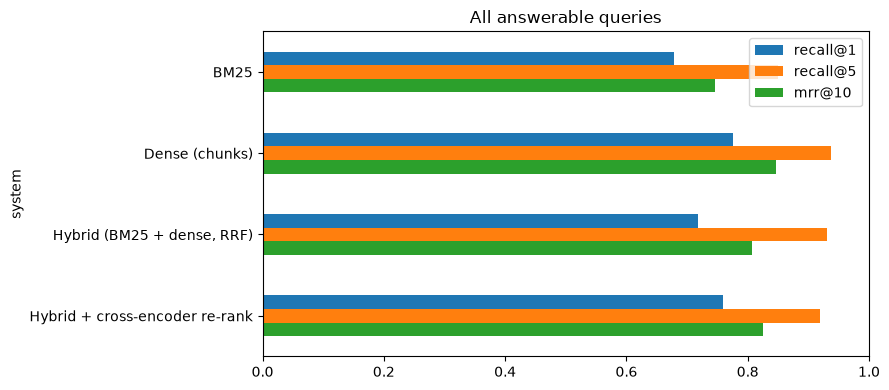

,recall@1,recall@5,recall@10,mrr@10,ndcg@10
system,,,,,
BM25,0.678,0.851,0.885,0.746,0.780
Dense (chunks),0.776,0.937,0.966,0.846,0.876
"Hybrid (BM25 + dense, RRF)",0.718,0.931,0.954,0.808,0.844
Hybrid + cross-encoder re-rank,0.759,0.920,0.937,0.825,0.852


In [13]:
METRICS = ["recall@1", "recall@5", "recall@10", "mrr@10", "ndcg@10"]
overall = runs.groupby("system", sort=False)[METRICS].mean()
ax = overall[["recall@1", "recall@5", "mrr@10"]].plot.barh(figsize=(9, 4), xlim=(0, 1))
ax.set_title("All answerable queries"); ax.invert_yaxis(); plt.tight_layout(); plt.show()
overall.round(3)

**The cross-encoder is not a clear win on our help center:**
- It does improve on its own input: hybrid Recall@1 0.718 → 0.759, and it has the best rank-1 accuracy on `keyword` (0.904) and `typo` (0.673) queries.
- But **dense retrieval alone is still better overall** (Recall@1 0.776, MRR 0.846 vs 0.825), and the re-ranker **hurts** paraphrases (0.673 vs 0.769) and template pages (`integration` 0.625 vs 0.875).
- Why? `ms-marco-MiniLM-L6-v2` was trained on Bing web-search queries and web passages. It strongly rewards passages that repeat the query's words: for "reset password" it puts two **release notes** first (one says "The password reset email has a new design"). It also confuses near-identical templates: for "unlink Dropbox from my account" it prefers "Connect Dropbox" over "Disconnect Dropbox".
- And it is slow: one transformer pass per candidate (Section 13).

**Lesson:** a pre-trained re-ranker is a hypothesis, not a guarantee. Companies fine-tune re-rankers on their own click logs or try stronger ones (e.g. the `bge-reranker` family), and they **always measure on their own queries**.

---
## 11. Error analysis, and a business rule

Numbers tell you **how much** is wrong; reading the failures tells you **what** to fix. Let us list the queries where the dense retriever (our best system so far) does not put the correct article first.

In [14]:
ID_TO_TITLE = dict(zip(corpus["doc_id"], corpus["title"]))
DOC_CATEGORY = dict(zip(corpus["doc_id"], corpus["category"]))
dense_rows = runs[runs["system"] == "Dense (chunks)"].merge(ANSWERABLE[["qid", "query", "relevant"]], on="qid")
misses = dense_rows[dense_rows["recall@1"] == 0].assign(
    top1_title=lambda d: d["top1"].map(ID_TO_TITLE),
    top1_category=lambda d: d["top1"].map(DOC_CATEGORY),
    correct_title=lambda d: d["relevant"].map(lambda r: ID_TO_TITLE[r[0]]))
pd.set_option("display.max_colwidth", 55)
print(f"{len(misses)} of {len(dense_rows)} queries do not have the correct article at rank 1")
print("Category of the wrong top-1 result:", misses["top1_category"].value_counts().to_dict())
misses[["type", "query", "top1_title", "correct_title"]].head(10)

39 of 174 queries do not have the correct article at rank 1
Category of the wrong top-1 result: {'Release notes': 16, 'Guides': 7, 'Invoices': 5, 'Integrations': 2, 'Billing': 2, 'Banking': 2, 'Account': 1, 'Team': 1, 'Tax': 1, 'Support': 1, 'Security': 1}


,type,query,top1_title,correct_title
6,keyword,enable two-factor authentication,Release notes - version 7.1,Turn on two-factor authentication (2FA)
8,typo,enabel two-factor authenticaiton,Release notes - version 7.34,Turn on two-factor authentication (2FA)
13,paraphrase,remove my whole profile and everything in it for good,Change the email address on your account,Delete your FinchBooks account
16,paraphrase,how can the person who does my bookkeeping get thei...,Remove a user from your workspace,Invite team members and your accountant
19,paraphrase,stop an employee from seeing bank details but let t...,Release notes - version 7.70,User roles and permissions
20,typo,user rples and petmissions,Security and Compliance Whitepaper,User roles and permissions
32,typo,cnacel suvscription,Release notes - version 7.20,Cancel your subscription
33,keyword,update payment method card,Accept online card payments on invoices,Update your payment method
38,typo,download subbscription rexeipts,Security and Compliance Whitepaper,Download receipts for your FinchBooks subscription
41,typo,requesst a refind,Reconcile bank transactions,Request a refund


**What the failures show:** of the 39 misses, **16** have a **release note** as the top result, by far the most common cause. Release notes repeat feature words ("Two-factor authentication now supports hardware security keys.") without explaining how to do anything, so every retriever finds them "relevant". The next group (7) are the long guides, which mention many topics in passing. Some misses are genuinely ambiguous (e.g. "remove my whole profile..." could mean deleting the account or changing details).

The fix is not a better model but a **business rule**: release notes and known-issue pages are not answers to "how do I...?" questions. Real help centers handle this with a separate "What's new" tab, a content-type filter, or a **score demotion**. We implement the simplest version: such pages are moved behind all other results (they still appear if nothing else matches).

> ⚠️ We found this rule by looking at failures of *this* query set, so the improvement we measure on the same queries is optimistic. That is why the next section chooses the final setup on one half of the queries and confirms it on the other half. In real life, you would also check it on fresh queries from the search logs.

In [15]:
NOT_ANSWERS = {"Release notes", "Known issues"}


def demote_non_answers(ranking: list[tuple[str, float]], doc_category: dict = DOC_CATEGORY) -> list[tuple[str, float]]:
    """Keep the order, but move release notes / known issues behind every other document."""
    answers = [r for r in ranking if doc_category[r[0]] not in NOT_ANSWERS]
    return answers + [r for r in ranking if doc_category[r[0]] in NOT_ANSWERS]


BASE_SYSTEMS = {"BM25": search_bm25, "Dense (chunks)": search_dense,
                "Hybrid (BM25 + dense, RRF)": search_hybrid, "Hybrid + cross-encoder re-rank": search_rerank}
for name in BASE_SYSTEMS:   # re-uses the cached rankings, so this is instant (no model calls)
    runs = pd.concat([runs, evaluate(lambda q, n=name: demote_non_answers(RANKINGS[(n, q)]), f"{name} + demote")])
summary(runs, "recall@1")

type,keyword,paraphrase,typo,deep_section,integration,ALL
system,,,,,,
BM25,0.846,0.538,0.635,0.9,0.500,0.678
Dense (chunks),0.885,0.769,0.635,0.9,0.875,0.776
"Hybrid (BM25 + dense, RRF)",0.885,0.615,0.596,1.0,0.750,0.718
Hybrid + cross-encoder re-rank,0.904,0.673,0.673,1.0,0.625,0.759
BM25 + demote,0.923,0.538,0.673,0.9,0.500,0.713
Dense (chunks) + demote,0.962,0.788,0.750,0.9,0.875,0.839
"Hybrid (BM25 + dense, RRF) + demote",0.962,0.635,0.692,1.0,0.750,0.776
Hybrid + cross-encoder re-rank + demote,0.962,0.673,0.731,1.0,0.625,0.793


---
## 12. Choosing the production setup honestly

We now have 8 candidate setups. If we picked the winner by looking at **all** queries and then reported its score on the same queries, we would be fooling ourselves (the same mistake as tuning on the test set in classic ML).

So we split the labelled queries into two halves, **stratified by query type**:
- **dev** half: used to *choose* the setup (by MRR@10),
- **test** half: used only to *report* how good the chosen setup is.

In [16]:
dev_qids = set(ANSWERABLE.loc[ANSWERABLE.groupby("type").cumcount() % 2 == 0, "qid"])   # every 2nd query per type
runs["part"] = np.where(runs["qid"].isin(dev_qids), "dev", "test")
selection = runs.pivot_table(index="system", columns="part", values=["recall@1", "recall@5", "mrr@10"], sort=False)
selection = selection.sort_values(("mrr@10", "dev"), ascending=False).round(3)

BEST_SYSTEM = selection.index[0]                     # chosen on dev only
best_test = selection.loc[BEST_SYSTEM].xs("test", level="part")
print(f"Chosen on dev queries: {BEST_SYSTEM}")
print(f"Its TEST results: Recall@1 {best_test['recall@1']:.3f} | Recall@5 {best_test['recall@5']:.3f} | "
      f"MRR@10 {best_test['mrr@10']:.3f}")
selection

Chosen on dev queries: Dense (chunks) + demote
Its TEST results: Recall@1 0.862 | Recall@5 0.977 | MRR@10 0.916


recall@1        recall@5         \
part                                         dev   test      dev   test   
system                                                                    
Dense (chunks) + demote                    0.816  0.862    0.989  0.977   
Hybrid (BM25 + dense, RRF) + demote        0.805  0.747    0.966  0.931   
Hybrid + cross-encoder re-rank + demote    0.816  0.770    0.943  0.943   
Hybrid + cross-encoder re-rank             0.759  0.759    0.920  0.920   
Hybrid (BM25 + dense, RRF)                 0.701  0.736    0.943  0.920   
Dense (chunks)                             0.713  0.839    0.931  0.943   
BM25 + demote                              0.713  0.713    0.885  0.839   
BM25                                       0.655  0.701    0.874  0.828   

                                        mrr@10         
part                                       dev   test  
system                                                 
Dense (chunks) + demote                  0.897  0.916  
Hybrid (BM25 + dense, RRF) + demote      0.880  0.821  
Hybrid + cross-encoder re-rank + demote  0.870  0.850  
Hybrid + cross-encoder re-rank           0.824  0.825  
Hybrid (BM25 + dense, RRF)               0.808  0.807  
Dense (chunks)                           0.805  0.887  
BM25 + demote                            0.791  0.767  
BM25                                     0.738  0.755

**The result:**
- The setup chosen on the dev queries is **dense retrieval + demotion of release notes / known issues**. On the held-out **test** queries it reaches **Recall@1 0.862, Recall@5 0.977, MRR@10 0.916**, against 0.701 / 0.828 / 0.755 for the BM25 baseline (the old keyword search).
- The **business rule helps every system** (overall Recall@1 +3 to +7 points), more than any model change we tried. In search, "boring" content rules often beat fancier models.
- It is also the best setup on the test half, so the choice is not a lucky accident. Notice how much other rows move between dev and test (e.g. hybrid + demote: MRR 0.880 → 0.821): with ~87 queries per half, differences of a few points are mostly **noise**. Collect more labelled queries before trusting small differences.
- The production setup needs **no BM25 and no cross-encoder** for ranking. Simpler is also cheaper and faster (next section).

In [17]:
def final_search(query: str) -> list[tuple[str, float]]:
    """The production ranking: the base system chosen above, plus the demotion rule if chosen."""
    base = BEST_SYSTEM.removesuffix(" + demote")
    ranking = BASE_SYSTEMS[base](query)
    return demote_non_answers(ranking) if BEST_SYSTEM.endswith(" + demote") else ranking


print([ID_TO_TITLE[d] for d, _ in final_search("I can't remember my password")[:3]])

['Reset your password', 'FinchBooks Administrator Handbook', 'Change the email address on your account']


---
## 13. Latency: what does each stage cost?

Users notice delays above ~100 to 200 ms. We time each search method on a sample of queries and report the **median (p50)** and the **95th percentile (p95)**: the p95 is what your slowest 5% of users experience.

In [18]:
def latency_ms(fn, texts: list[str]) -> dict:
    times = []
    for t in texts:
        start = time.perf_counter()
        fn(t)
        times.append((time.perf_counter() - start) * 1000)
    return {"p50_ms": round(float(np.percentile(times, 50)), 1), "p95_ms": round(float(np.percentile(times, 95)), 1)}


sample = queries["query"].sample(30, random_state=CFG.random_state).tolist()
print(f"CPU load average while measuring: {os.getloadavg()[0]:.1f} (this machine has {os.cpu_count()} cores)")
latency = pd.DataFrame({name: latency_ms(fn, sample) for name, fn in BASE_SYSTEMS.items()}).T
latency.join(overall[["recall@1", "recall@5"]].round(3))

CPU load average while measuring: 12.5 (this machine has 8 cores)


,p50_ms,p95_ms,recall@1,recall@5
BM25,0.6,1.3,0.678,0.851
Dense (chunks),17.5,21.8,0.776,0.937
"Hybrid (BM25 + dense, RRF)",18.5,21.4,0.718,0.931
Hybrid + cross-encoder re-rank,304.7,355.4,0.759,0.920


**Reading the latency table** (measured while the machine was busy with other jobs, load ≈ 12 on 8 cores, so treat the numbers as pessimistic):
- BM25 is almost free (< 2 ms). Dense retrieval costs ≈ 18 ms, almost all of it to embed the query; the FAISS search itself is tiny.
- The cross-encoder adds ≈ 300 ms per query (15 extra transformer passes), about 17× slower than dense retrieval, and here it did not even improve quality.
- Our production setup (dense + demotion) costs the same as dense retrieval: comfortably inside a 100 ms budget on a CPU.

---
## 14. "No good answer" detection with a score threshold

A search engine always returns *something*: even for "best pizza dough recipe" it will happily show the closest accounting article. For a help center (and even more for a RAG chatbot, which would then *invent* an answer from irrelevant text) we want to say **"we couldn't find an answer, contact support"** instead.

Simple and effective: look at the **score of the top result**. If it is below a threshold, flag "no good answer". We compare two scores for the top result of our production ranking:
- `final_top`: the score the production system already computed (free),
- `cross_top1`: the cross-encoder score of (query, best chunk of the top result): one extra model call per search.

We choose each threshold on the **dev** queries and measure on the **test** queries (each half has 10 `no_answer` queries, so expect some noise).

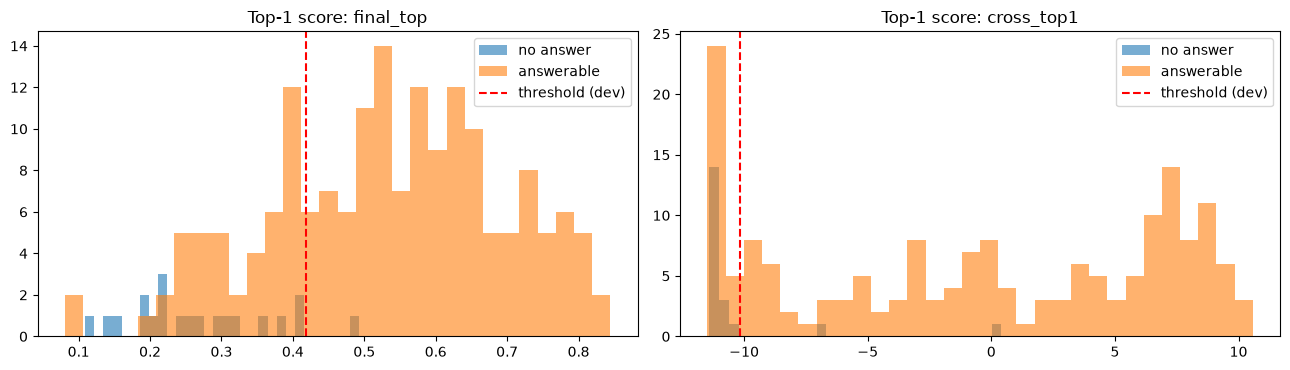

Chosen 'no good answer' signal: cross_top1 < -10.175


,threshold,dev_balanced_acc,answerable_kept (test),no_answer_caught (test)
score,,,,
final_top,0.418,0.868,0.747,0.9
cross_top1,-10.175,0.920,0.839,0.8


In [19]:
def top_scores(query: str) -> dict:
    doc_id, score = final_search(query)[0]
    passage = CHUNK_TEXTS[best_chunk_for(embed([query])[0], doc_id)]
    return {"final_top": score, "cross_top1": float(cross_encoder.predict([(query, passage)], show_progress_bar=False)[0])}


scored = queries.join(pd.DataFrame([top_scores(q) for q in queries["query"]]))
scored["has_answer"] = scored["type"] != "no_answer"
dev_mask = scored.groupby("type").cumcount() % 2 == 0          # same dev/test rule as in Section 12
dev, test = scored[dev_mask], scored[~dev_mask]


def balanced_accuracy(scores: pd.Series, has_answer: pd.Series, t: float) -> float:
    keep = scores >= t
    return 0.5 * ((keep & has_answer).sum() / has_answer.sum() + (~keep & ~has_answer).sum() / (~has_answer).sum())


rows = []
for col in ["final_top", "cross_top1"]:
    t = float(max(np.unique(dev[col]), key=lambda c: balanced_accuracy(dev[col], dev["has_answer"], c)))
    keep = test[col] >= t
    rows.append({"score": col, "threshold": round(t, 3),
                 "dev_balanced_acc": round(balanced_accuracy(dev[col], dev["has_answer"], t), 3),
                 "answerable_kept (test)": round(float((keep & test["has_answer"]).sum() / test["has_answer"].sum()), 3),
                 "no_answer_caught (test)": round(float((~keep & ~test["has_answer"]).sum() / (~test["has_answer"]).sum()), 3)})
threshold_table = pd.DataFrame(rows).set_index("score")
ANSWER_SCORE = threshold_table["dev_balanced_acc"].idxmax()        # chosen on dev
ANSWER_THRESHOLD = float(threshold_table.loc[ANSWER_SCORE, "threshold"])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, col in zip(axes, ["final_top", "cross_top1"]):
    for label, part in scored.groupby("has_answer"):
        ax.hist(part[col], bins=30, alpha=0.6, label="answerable" if label else "no answer")
    ax.axvline(threshold_table.loc[col, "threshold"], color="red", ls="--", label="threshold (dev)")
    ax.set_title(f"Top-1 score: {col}"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Chosen 'no good answer' signal: {ANSWER_SCORE} < {ANSWER_THRESHOLD:.3f}")
threshold_table

**Reading the result:**
- On the dev queries the cross-encoder score of the top result separates answerable from unanswerable queries better (balanced accuracy 0.92 vs 0.87), so the service uses it: **one** extra cross-encoder call per search (not 15), which is a reasonable price for this feature.
- On the test half it keeps **84%** of answerable queries and catches **8 of the 10** out-of-scope queries. The dense score would catch 9 of 10 but wrongly flag a quarter of the answerable queries.
- Where to put the threshold is a **business decision**: a false "no answer" hides a good article (we still show the results, plus a "contact us" button), while a missed one shows irrelevant articles or, in a RAG chatbot, lets the LLM invent an answer. With only 10 unanswerable test queries these rates are rough estimates; real teams collect hundreds from search logs ("searches followed by a ticket").

---
## 15. Save and reload the index

Embedding a big corpus can take hours, so you **never** re-embed at every application start. You build the index in an offline job and save:
- the FAISS index (`faiss.write_index`),
- the chunk table (ids, titles, texts, categories) as JSON,
- **metadata**: which embedding model, its dimension, normalisation, chunking settings, a fingerprint of the corpus, and the **search configuration chosen by the evaluation** (Sections 12 and 14). Mixing vectors from two different models is a classic, silent production bug: the metadata lets the service refuse to start if they don't match.

BM25 statistics are cheap, so we simply rebuild them from the chunk texts at load time. In a real project, these files would go to `indexes/help_center/2026-10-21/` or object storage (S3), or the vectors would live in a vector database (see `../13_Databases/03_vector_db/01_vector_databases.ipynb`).

In [20]:
INDEX_DIR = Path(tempfile.mkdtemp(prefix="kb_index_"))       # real life: indexes/help_center/<date>/
faiss.write_index(index, str(INDEX_DIR / "chunks.faiss"))
chunks.to_json(INDEX_DIR / "chunks.json", orient="records", indent=1)
base = BEST_SYSTEM.removesuffix(" + demote")
index_meta = {
    "built_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "bi_encoder": CFG.bi_encoder, "cross_encoder": CFG.cross_encoder,
    "embedding_dim": int(chunk_vectors.shape[1]), "normalized": True,
    "n_documents": int(corpus["doc_id"].nunique()), "n_chunks": int(len(chunks)),
    "corpus_fingerprint": hashlib.sha256("".join(chunks["text"]).encode()).hexdigest()[:16],
    "search_config": {                                   # decided by the offline evaluation
        "system": BEST_SYSTEM,
        "use_dense": base != "BM25",
        "use_bm25": base.startswith(("BM25", "Hybrid")),
        "rerank": "re-rank" in base,
        "demote_non_answers": BEST_SYSTEM.endswith(" + demote"),
        "no_answer_score": ANSWER_SCORE, "no_answer_threshold": ANSWER_THRESHOLD,
    },
    "test_metrics": {k: float(v) for k, v in best_test.items()},
    "config": asdict(CFG),
}
(INDEX_DIR / "index_meta.json").write_text(json.dumps(index_meta, indent=2))
for f in sorted(INDEX_DIR.iterdir()):
    print(f"{f.name:18s} {f.stat().st_size / 1024:8.1f} KB")
print(json.dumps(index_meta["search_config"], indent=2))

chunks.faiss          408.0 KB
chunks.json           150.3 KB
index_meta.json         0.9 KB
{
  "system": "Dense (chunks) + demote",
  "use_dense": true,
  "use_bm25": false,
  "rerank": false,
  "demote_non_answers": true,
  "no_answer_score": "cross_top1",
  "no_answer_threshold": -10.175
}


---
## 16. The search API: validated input, snippets, answer flag

The `HelpCenterSearch` class is what a web service (FastAPI, see `../12_FastAPI/`) would load **once** at start-up. It:
1. loads the saved index and checks the metadata (right model, right dimension, right number of chunks),
2. validates the request with **Pydantic** (empty or 1,000-character queries are rejected),
3. runs exactly the search configuration stored in the metadata (so changing the setup is a config change, not a code change),
4. returns, for each result, a **snippet**: the best sentence of the best chunk, with query words highlighted,
5. sets `no_good_answer=True` when the answer score is below the threshold.

In [21]:
from pydantic import BaseModel, Field, ValidationError


class SearchRequest(BaseModel):
    query: str = Field(min_length=2, max_length=300)    # reject empty and absurdly long queries
    k: int = Field(default=5, ge=1, le=20)              # how many results to return


class HelpCenterSearch:
    def __init__(self, index_dir: Path):
        self.meta = json.loads((index_dir / "index_meta.json").read_text())
        self.cfg = self.meta["search_config"]
        self.encoder = SentenceTransformer(self.meta["bi_encoder"], device="cpu")
        self.reranker = CrossEncoder(self.meta["cross_encoder"], device="cpu")
        self.index = faiss.read_index(str(index_dir / "chunks.faiss"))
        self.chunks = pd.read_json(index_dir / "chunks.json", orient="records")
        # Refuse to start with a mismatched index: a silent, common production bug
        assert self.index.d == self.encoder.get_sentence_embedding_dimension() == self.meta["embedding_dim"]
        assert self.index.ntotal == len(self.chunks) == self.meta["n_chunks"]
        self.vectors = self.index.reconstruct_n(0, self.index.ntotal)        # chunk vectors, for best-chunk lookup
        self.bm25 = BM25Okapi([tokenize(t) for t in self.chunks["text"]])
        self.doc_chunks = self.chunks.groupby("doc_id").indices
        self.doc_category = dict(zip(self.chunks["doc_id"], self.chunks["category"]))
        log.info("Search service ready: %d chunks | %s", self.index.ntotal, self.cfg["system"])

    def _per_doc(self, chunk_idx, scores) -> list[tuple[str, float]]:
        best = {}
        for i, s in zip(chunk_idx, scores):
            d = self.chunks.at[int(i), "doc_id"]
            best[d] = max(best.get(d, -np.inf), float(s))       # a document keeps its best chunk score
        return sorted(best.items(), key=lambda kv: kv[1], reverse=True)

    def _best_chunk(self, q_vec: np.ndarray, doc_id: str) -> int:
        rows = self.doc_chunks[doc_id]
        return int(rows[np.argmax(self.vectors[rows] @ q_vec)])

    @staticmethod
    def _snippet(query: str, body: str, max_chars: int = 220) -> str:
        """Pick the sentence with the most query words and **highlight** them."""
        sentences = re.split(r"(?<=[.!?])\s+", body)
        q_terms = set(tokenize(query))
        best = max(sentences, key=lambda s: len(q_terms & set(tokenize(s))))
        highlighted = re.sub(r"[A-Za-z0-9]+", lambda m: f"**{m.group(0)}**"
                             if stemmer.stem(m.group(0).lower()) in q_terms else m.group(0), best)
        return highlighted[:max_chars]

    def search(self, payload: dict) -> dict:
        start = time.perf_counter()
        req = SearchRequest(**payload)                                        # raises ValidationError
        q_vec = self.encoder.encode([req.query], normalize_embeddings=True,
                                    show_progress_bar=False).astype("float32")
        rankings = []
        if self.cfg["use_bm25"]:
            bm = self.bm25.get_scores(tokenize(req.query))
            top = np.argsort(bm)[::-1][:CFG.candidates]
            rankings.append(self._per_doc(top, bm[top]))
        if self.cfg["use_dense"]:
            scores, idx = self.index.search(q_vec, CFG.candidates)
            rankings.append(self._per_doc(idx[0], scores[0]))
        ranked = rankings[0] if len(rankings) == 1 else reciprocal_rank_fusion(rankings)
        if self.cfg["rerank"]:
            cands = [d for d, _ in ranked[:CFG.rerank_depth]]
            ce = self.reranker.predict([(req.query, self.chunks.at[self._best_chunk(q_vec[0], d), "text"])
                                        for d in cands], show_progress_bar=False)
            ranked = sorted(zip(cands, map(float, ce)), key=lambda kv: kv[1], reverse=True)
        if self.cfg["demote_non_answers"]:
            ranked = demote_non_answers(ranked, self.doc_category)
        top_results = ranked[:req.k]
        best_chunks = [self._best_chunk(q_vec[0], d) for d, _ in top_results]
        if self.cfg["no_answer_score"] == "cross_top1":
            answer_score = float(self.reranker.predict([(req.query, self.chunks.at[best_chunks[0], "text"])],
                                                       show_progress_bar=False)[0])
        else:
            answer_score = top_results[0][1]
        results = [{"doc_id": d, "title": self.chunks.at[c, "title"], "score": round(s, 3),
                    "snippet": self._snippet(req.query, self.chunks.at[c, "body"])}
                   for (d, s), c in zip(top_results, best_chunks)]
        return {"query": req.query, "no_good_answer": bool(answer_score < self.cfg["no_answer_threshold"]),
                "answer_score": round(answer_score, 3), "results": results,
                "latency_ms": round((time.perf_counter() - start) * 1000, 1)}


service = HelpCenterSearch(INDEX_DIR)            # simulates a fresh start of the web service
for q in ["I can't remember my password", "how often do you back up my data", "best pizza dough recipe"]:
    response = service.search({"query": q, "k": 3})
    print(f"\nQUERY: {q!r} | no_good_answer={response['no_good_answer']} "
          f"(score {response['answer_score']}) | {response['latency_ms']} ms")
    for r in response["results"]:
        print(f"  [{r['score']:7.3f}] {r['doc_id']} {r['title']}\n            {r['snippet']}")

2026-10-21 17:49:25,150 | INFO | Search service ready: 272 chunks | Dense (chunks) + demote



QUERY: "I can't remember my password" | no_good_answer=False (score 1.19) | 217.1 ms
  [  0.495] KB-001 Reset your password
            If you forgot your **password**, click 'Forgot **password**?' on the sign-in page and enter the email address of your FinchBooks account.
  [  0.355] KB-090 FinchBooks Administrator Handbook
            Admins can enforce a **password** policy for all users: a minimum length of 12 to 32 characters, required symbols, and **password** expiry after 30, 60 or 90 days.
  [  0.344] KB-002 Change the email address on your account
            Go to Profile > Login details and click Edit next to your email address.

QUERY: 'how often do you back up my data' | no_good_answer=False (score 1.2) | 84.2 ms
  [  0.524] KB-042 How long we keep your data after you cancel
            After cancellation your **data** stays in read-only mode for 12 months so you can export it.
  [  0.466] KB-041 Request a copy of your personal data (GDPR)
            Under the GDPR you c

The first query (a paraphrase that is **not** in our labelled set) finds the right article, and the out-of-scope pizza question is flagged. The second one is an honest partial failure: the answer ("We back up all data every six hours") is in the Administrator Handbook, but it only comes **third**, after two privacy articles (data retention after cancellation, GDPR data copy) that are also "about my data". This is exactly what Recall@5 versus Recall@1 measures. The snippet makes the answer visible on the results page anyway, which is why good snippets matter.

In [22]:
# The reloaded service must give the same top result as the in-notebook pipeline (no silent drift)
same = sum(service.search({"query": q, "k": 1})["results"][0]["doc_id"] == final_search(q)[0][0]
           for q in ANSWERABLE["query"].head(30))
print(f"Same top-1 result for {same}/30 queries after saving and reloading the index")

for bad in [{"query": ""}, {"query": "x" * 1000}, {"query": "reset password", "k": 500}]:
    try:
        service.search(bad)
    except ValidationError as err:
        print("Rejected:", "; ".join(f"{e['loc'][0]}: {e['msg']}" for e in err.errors()))

Same top-1 result for 30/30 queries after saving and reloading the index
Rejected: query: String should have at least 2 characters
Rejected: query: String should have at most 300 characters
Rejected: k: Input should be less than or equal to 20


---
## 17. Scaling up and automated tests

### From a few hundred chunks to 60 million
`IndexFlatIP` compares the query with **every** vector. That is perfect here, but at millions of vectors you switch to an **approximate nearest neighbour (ANN)** index, which trades a tiny bit of recall for a big speed-up. The most popular is **HNSW** (a graph you can walk quickly), used by FAISS, Qdrant, Weaviate, pgvector and Elasticsearch. A quick check that HNSW finds the same neighbours as exact search:

In [23]:
hnsw = faiss.IndexHNSWFlat(chunk_vectors.shape[1], 32, faiss.METRIC_INNER_PRODUCT)  # 32 links per node
hnsw.hnsw.efSearch = 64                     # larger = more accurate, slower
hnsw.add(chunk_vectors)
query_vecs = embed(ANSWERABLE["query"].tolist())
_, exact_ids = index.search(query_vecs, 10)
_, ann_ids = hnsw.search(query_vecs, 10)
overlap = np.mean([len(set(a) & set(e)) / 10 for a, e in zip(ann_ids, exact_ids)])
print(f"HNSW finds {overlap:.1%} of the exact top-10 neighbours")

HNSW finds 99.9% of the exact top-10 neighbours


### Automated tests
In a real repository these run in CI every time the corpus, the chunker or the model changes. The most important one is the **quality gate**: a new index must not be worse than the current one (here: the BM25 baseline) on the labelled query set.

In [24]:
def test_chunks_respect_model_limit():
    longest = max(len(bi_encoder.tokenizer(t)["input_ids"]) for t in chunks["text"])
    assert longest <= bi_encoder.max_seq_length, longest


def test_every_document_is_indexed():
    assert set(chunks["doc_id"]) == set(corpus["doc_id"]) and index.ntotal == len(chunks)


def test_exact_title_is_found():
    for title in ["Cancel your subscription", "Set up webhooks", "Track mileage for business trips"]:
        assert service.search({"query": title, "k": 3})["results"][0]["title"] == title


def test_out_of_scope_query_is_flagged():
    assert service.search({"query": "how many calories in a banana"})["no_good_answer"]


def test_quality_gate():
    """The production setup must beat the BM25 baseline on the TEST queries."""
    assert selection.loc[BEST_SYSTEM, ("mrr@10", "test")] > selection.loc["BM25", ("mrr@10", "test")]


for test in [test_chunks_respect_model_limit, test_every_document_is_indexed, test_exact_title_is_found,
             test_out_of_scope_query_is_flagged, test_quality_gate]:
    test()
    print(f"PASSED  {test.__name__}")

PASSED  test_chunks_respect_model_limit
PASSED  test_every_document_is_indexed


PASSED  test_exact_title_is_found
PASSED  test_out_of_scope_query_is_flagged
PASSED  test_quality_gate


---
## 18. Summary, exercises and resources

| Practice | What we did | Where it is used in industry |
|---|---|---|
| Labelled query set by type | keyword / paraphrase / typo / deep section / template / no answer | Search-quality teams, BEIR-style benchmarks |
| Keyword baseline first | BM25 with stemming | Elasticsearch, OpenSearch, Solr |
| Chunking with title prefix | ~110-word overlapping chunks | Every RAG system and vector search |
| Dense retrieval | MiniLM embeddings + FAISS (our winner) | Vector databases (FAISS, Qdrant, pgvector, Pinecone) |
| Hybrid search | Reciprocal Rank Fusion, k = 60 (helped typos, hurt paraphrases here) | Elasticsearch/OpenSearch/Weaviate hybrid queries |
| Retrieve & re-rank | Cross-encoder on the top 15 (measured, not chosen: no gain on our data) | Web search, e-commerce search, RAG |
| Error analysis → business rule | Demote release notes / known issues | Content-type boosts and filters in every help center |
| Honest model selection | Choose on dev queries, report on test queries | Offline evaluation before A/B tests |
| Latency budget | p50 / p95 per stage | SLOs of search services |
| "No good answer" | Threshold on the cross-encoder score of the top result, chosen on dev queries | Help centers, RAG guardrails |
| Index persistence + metadata | FAISS file, chunks, model name, fingerprint, chosen search config | Offline indexing jobs, safe deployments |
| Validated API with snippets | Pydantic request, highlighted snippets | Search microservices |
| ANN for scale | HNSW vs exact | Million-scale vector search |
| Tests | Token-limit, coverage, quality gate | CI for search |

### Practice exercises
1. Remove the title prefix from the chunks (`prefix = ""`) and re-run. Which query types suffer?
2. Change `chunk_words` to 50 and to 200. What happens to `deep_section` recall and to the number of chunks?
3. Try a stronger embedding model such as `BAAI/bge-small-en-v1.5` (~130 MB). Does it beat MiniLM on paraphrases?
4. Change the weights in RRF (e.g. count the dense ranking twice). Does hybrid search then beat dense retrieval?
5. Add a synonym list (`"login" -> "sign in"`) to the BM25 tokenizer, a classic trick in keyword search.
6. Connect `HelpCenterSearch` to an LLM to generate an answer from the top 3 chunks (see `../08_LLM/02_rag/`), and **don't** call the LLM when `no_good_answer` is true.

### Resources
- Sentence Transformers: [Semantic search](https://sbert.net/examples/sentence_transformer/applications/semantic-search/README.html) and [Retrieve & Re-Rank](https://sbert.net/examples/sentence_transformer/applications/retrieve_rerank/README.html)
- Models used: [all-MiniLM-L6-v2](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2), [ms-marco-MiniLM-L6-v2 cross-encoder](https://huggingface.co/cross-encoder/ms-marco-MiniLM-L6-v2)
- Hugging Face LLM Course: [Semantic search with FAISS](https://huggingface.co/learn/llm-course/chapter5/6)
- [BEIR benchmark](https://github.com/beir-cellar/beir) (Thakur et al., 2021): why BM25 is a strong baseline and how retrieval is evaluated
- [rank_bm25](https://github.com/dorianbrown/rank_bm25) and the [FAISS wiki](https://github.com/facebookresearch/faiss/wiki); Pinecone's [FAISS tutorial series](https://www.pinecone.io/learn/series/faiss/)
- Cormack, Clarke & Büttcher (2009): [Reciprocal Rank Fusion outperforms Condorcet and individual rank learning methods](https://plg.uwaterloo.ca/~gvcormac/cormacksigir09-rrf.pdf); Weaviate: [Hybrid search explained](https://weaviate.io/blog/hybrid-search-explained)
- [MTEB leaderboard](https://huggingface.co/spaces/mteb/leaderboard) to choose embedding models

### Related notebooks in this repo
- Sentence embeddings (theory): [`09_sentence_embeddings_advanced.ipynb`](09_sentence_embeddings_advanced.ipynb)
- BM25 vs dense retrieval (theory): [`10_advanced_nlp_tasks.ipynb`](10_advanced_nlp_tasks.ipynb)
- Question answering: [`06_question_answering.ipynb`](06_question_answering.ipynb)
- Companion project, ticket routing: [`12_industry_support_ticket_routing.ipynb`](12_industry_support_ticket_routing.ipynb)
- RAG: [`../08_LLM/02_rag/01_rag_fundamentals.ipynb`](../08_LLM/02_rag/01_rag_fundamentals.ipynb), [`../08_LLM/02_rag/04_advanced_retrieval_and_reranking.ipynb`](../08_LLM/02_rag/04_advanced_retrieval_and_reranking.ipynb)
- Vector databases: [`../13_Databases/03_vector_db/01_vector_databases.ipynb`](../13_Databases/03_vector_db/01_vector_databases.ipynb), [`../22_ML_System_Design/05_vector_databases.ipynb`](../22_ML_System_Design/05_vector_databases.ipynb)